## Kalman filter for implied vol estimation

In [1]:

import os
os.environ.setdefault("POLARS_SKIP_CPU_CHECK", "1")

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.massive.client
%aimport quantdata.massive.processing
%aimport quantdata.massive.options.contracts
%aimport quantdata.ncde.implied.day

In [2]:
"""
Load day
"""

from datetime import date
from cdxcore.subdir import SubDir
from cdxcore.util import fmt_list
from cdxcore.uniquehash import named_unique_filename48_8
import polars as pl

from quantdata.biz_calendar import prev_business_day
from quantdata.pool import PoolConfig
from cdxcore.version import version
from cdxcore.verbose import Context
from dataclasses import asdict, dataclass, field
from cdxcore.uniquehash import unique_hash8 
import numpy as np
import math
import warnings

from IPython.display import display, Markdown, clear_output

from quantdata.ncde.implied.day import OptionQuotesDayConfig, generate_day

option_quotes_day_config = OptionQuotesDayConfig()
ticker     = "SPY"
d          = prev_business_day(date(2025,1,23), exclude_half_days=True, count_start=True )
pool_config= PoolConfig(num_workers=4, threading=False) 
results    = generate_day( ticker, d, option_quotes_day_config=option_quotes_day_config, pool_config=pool_config, verbose=Context.all )

print(sorted(results))

00: SPY 2025-01-23: Starting data generation with config mxn=1000,max_dte=7,max_mns=2,min_opt_vol_k=0,bck=250,fwd=250):
00: SPY 2025-01-23: Limiting to at most 1000 options per expiry, selected by smallest absolute nms5:
01:   SPY 2025-01-23 expiry 2025-01-23: Selected 32/32 options, sorted by smallest absolute nms5. Resulting options range from nms5 -0.848 to 0.851.
01:   SPY 2025-01-23 expiry 2025-01-24: Selected 52/52 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.104 to 1.097.
01:   SPY 2025-01-23 expiry 2025-01-27: Selected 50/50 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.233 to 1.219.
01:   SPY 2025-01-23 expiry 2025-01-28: Selected 54/54 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.351 to 1.330.
01:   SPY 2025-01-23 expiry 2025-01-29: Selected 59/59 options, sorted by smallest absolute nms5. Resulting options range from nms5 -1.372 to 1.433.
01:   SPY 2025-01-23 expiry 2025-0

In [16]:
opt_ticker = "O:SPY250123C00612000"#"O:SPY250123C00599000"
expiry = date(2025,1,23)
opt_df = results[expiry].filter(pl.col("opt_ticker") == opt_ticker)

opt_df = opt_df.with_columns(
    (( pl.col("mid_price") + pl.col("half_spread") ) * pl.col("prev_spot_close")).alias("cash_ask"),
    (( pl.col("mid_price") - pl.col("half_spread") ) * pl.col("prev_spot_close")).alias("cash_bid"),
    ( pl.col("opt_tick_size") * pl.col("prev_spot_close") ).alias("cash_tick_size"),
    (( pl.col("spot_mid_price") - pl.col("spot_half_spread") ) * pl.col("prev_spot_close") ).alias("spot_cash_bid"),
    (( pl.col("spot_mid_price") + pl.col("spot_half_spread") ) * pl.col("prev_spot_close") ).alias("spot_cash_ask"),
    ( pl.col("intrinsic") * pl.col("prev_spot_close") ).alias("cash_intrinsic"),
    ( pl.col("strike")* pl.col("prev_spot_close") ).alias("cash_strike"),
    ( pl.col("strike") / pl.col("spot_mid_price") ).alias("moneyness")
).with_columns(
    (pl.col("spot_cash_ask") - pl.col("cash_strike")).alias("ask_intrinsic")
)

display(opt_df.tail(100))

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,trade_dte,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol,trade_vol,trade_delta,trade_gamma,trade_vega,trade_theta,paired_opt_ticker,cash_ask,cash_bid,cash_tick_size,spot_cash_bid,spot_cash_ask,cash_intrinsic,cash_strike,moneyness,ask_intrinsic
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,1.002655,6.0,0.617434,null,0.61743,0.61743,0.000025,0.000008,1.002655,0.000016,27603.0,0.482303,1400.0,0.5,null,0.0,0.0,null,-0.000132,-0.000132,0.306053,0.000578,null,null,0.000577,0.000578,0.472816,2025-01-23,2025-01-23,1.009168,"""SPY""","""O:SPY250123C00612000""",true,true,606.44,0.000016,0.0,true,0.015566,12.988039,0.001366,0.048448,0.086145,0.026644,18.365434,0.002154,0.085183,0.096059,0.021072,15.852495,0.001768,0.066513,0.091362,NaN,NaN,NaN,NaN,NaN,"""O:SPY250123P00612000""",0.02,0.01,0.01,608.04,608.06,0.0,612.0,1.006496,-3.94
null,null,1.002721,100.0,0.617971,null,0.617971,0.617971,0.000025,0.000008,1.002729,0.000008,28581.0,0.482943,1400.0,0.142857,null,-1.0,0.0,null,0.000066,0.000074,0.305623,0.000537,null,null,0.000541,0.000541,0.467431,2025-01-23,2025-01-23,1.009168,"""SPY""","""O:SPY250123C00612000""",true,true,606.44,0.000016,0.0,true,0.0157,13.212855,0.001375,0.048394,0.085355,0.026848,18.663381,0.002166,0.085021,0.095192,0.021253,16.122642,0.00178,0.066445,0.090541,NaN,NaN,NaN,NaN,NaN,"""O:SPY250123P00612000""",0.02,0.01,0.01,608.09,608.1,0.0,612.0,1.006422,-3.9
null,null,1.00277,14.0,0.618481,null,0.618481,0.618481,0.000025,0.000008,1.002762,0.000025,27642.0,0.469792,1800.0,0.277778,null,0.333333,0.0,null,0.000049,0.000033,0.305215,0.00051,null,null,0.00051,0.00051,0.465048,2025-01-23,2025-01-23,1.009168,"""SPY""","""O:SPY250123C00612000""",true,true,606.44,0.000016,0.0,true,0.01576,13.314849,0.001379,0.048404,0.085034,0.026941,18.798483,0.002171,0.085009,0.094839,0.021334,16.245144,0.001785,0.066462,0.090208,NaN,NaN,NaN,NaN,NaN,"""O:SPY250123P00612000""",0.02,0.01,0.01,608.1,608.13,0.0,612.0,1.006389,-3.87
null,null,1.00282,1.0,0.61929,null,0.619286,0.619286,0.000025,0.000008,1.002828,0.000025,24328.0,0.516442,1700.0,0.588235,null,-0.333333,0.0,null,0.000049,0.000066,0.304568,0.000808,null,null,0.000805,0.000805,0.460272,2025-01-23,2025-01-23,1.009168,"""SPY""","""O:SPY250123C00612000""",true,true,606.44,0.000016,0.0,true,0.015882,13.522788,0.001387,0.048398,0.084366,0.027128,19.073789,0.002182,0.084938,0.094107,0.0215,16.494787,0.001795,0.066458,0.089513,NaN,NaN,NaN,NaN,NaN,"""O:SPY250123P00612000""",0.02,0.01,0.01,608.14,608.17,0.0,612.0,1.006322,-3.83
null,null,1.00282,1.0,0.61929,null,0.619286,0.619286,0.000025,0.000008,1.002828,0.000025,28471.0,0.48653,1700.0,0.588235,null,-0.333333,0.0,null,0.0,0.0,0.304568,3.0047e-7,null,null,0.0,0.0,0.460273,2025-01-23,2025-01-23,1.009168,"""SPY""","""O:SPY250123C00612000""",true,true,606.44,0.000016,0.0,true,0.015882,13.522788,0.001387,0.048398,0.084366,0.027128,19.073789,0.002182,0.084938,0.094107,0.0215,16.494787,0.001795,0.066458,0.089513,NaN,NaN,NaN,NaN,NaN,"""O:SPY250123P00612000""",0.02,0.01,0.01,608.14,608.17,0.0,612.0,1.006322,-3.83
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,1.002358,13

In [ ]:
opt_ticker = "O:SPY250123P00609000"
expiry = date(2025,1,23)
opt_df = results[expiry].filter(pl.col("opt_ticker") == opt_ticker)

opt_df = opt_df.with_columns(
    (( pl.col("mid_price") + pl.col("half_spread") ) * pl.col("prev_spot_close")).alias("cash_ask"),
    (( pl.col("mid_price") - pl.col("half_spread") ) * pl.col("prev_spot_close")).alias("cash_bid"),
    ( pl.col("opt_tick_size") * pl.col("prev_spot_close") ).alias("cash_tick_size"),
    (( pl.col("spot_mid_price") - pl.col("spot_half_spread") ) * pl.col("prev_spot_close") ).alias("spot_cash_bid"),
    (( pl.col("spot_mid_price") + pl.col("spot_half_spread") ) * pl.col("prev_spot_close") ).alias("spot_cash_ask"),
    ( pl.col("intrinsic") * pl.col("prev_spot_close") ).alias("cash_intrinsic"),
    ( pl.col("strike")* pl.col("prev_spot_close") ).alias("cash_strike"),
    ( pl.col("strike") / pl.col("spot_mid_price") ).alias("moneyness")
).with_columns(
    (pl.col("cash_strike") - pl.col("spot_cash_ask")).alias("ask_intrinsic"),
    (pl.col("cash_strike") - pl.col("spot_cash_bid")).alias("bid_intrinsic")
)

display(opt_df.tail(100))

trade_price,trade_size,spot_trade_price,spot_trade_size,t_d,trade_t_d,spot_trade_t_d,spot_quote_t_d,mid_price,half_spread,spot_mid_price,spot_half_spread,size,bid_size_pcnt,spot_size,spot_bid_size_pcnt,trade_direction,spot_trade_direction,mid_ret,trade_ret,spot_trade_ret,spot_mid_ret,dte,dt_d,trade_dt_d,trade_dte,spot_trade_dt_d,spot_quote_dt_d,nms5,exp_date,date,strike,ticker,opt_ticker,is_american,is_call,prev_spot_close,opt_tick_size,intrinsic,is_intrinsic,bid_delta,bid_gamma,bid_vega,bid_theta,bid_vol,ask_delta,ask_gamma,ask_vega,ask_theta,ask_vol,mid_delta,mid_gamma,mid_vega,mid_theta,mid_vol,trade_vol,trade_delta,trade_gamma,trade_vega,trade_theta,paired_opt_ticker,cash_ask,cash_bid,cash_tick_size,spot_cash_bid,spot_cash_ask,cash_intrinsic,cash_strike,moneyness,ask_intrinsic,bid_intrinsic
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,date,f64,str,str,bool,bool,f64,f64,f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,1.005112,5.0,0.999422,null,0.99942,0.99942,0.000091,0.000008,1.005095,0.000016,767.0,0.413299,2200.0,0.5,null,1.0,0.0,null,1.6406e-7,0.0,0.000463,0.000009,null,null,0.000008,0.000011,-0.065432,2025-01-23,2025-01-23,1.004221,"""SPY""","""O:SPY250123P00609000""",true,false,606.44,0.000016,0.0,false,-0.170013,276.025551,0.000345,63.196463,0.673255,-0.185878,273.339599,0.000365,71.419257,0.719224,-0.178173,274.898913,0.000355,67.352615,0.696464,NaN,NaN,NaN,NaN,NaN,"""O:SPY250123C00609000""",0.06,0.05,0.01,609.52,609.54,0.0,609.0,0.99913,-0.54,-0.52
null,null,1.005079,200.0,0.999422,null,0.999422,0.999422,0.000091,0.000008,1.005087,0.000008,827.0,0.455865,300.0,0.666667,null,-1.0,0.0,null,-0.000033,-0.000008,0.000462,4.8684e-7,null,null,0.000002,0.000003,-0.064815,2025-01-23,2025-01-23,1.004221,"""SPY""","""O:SPY250123P00609000""",true,false,606.44,0.000016,0.0,false,-0.170811,278.570644,0.000346,63.048477,0.669393,-0.18673,275.742553,0.000365,71.259531,0.715288,-0.179002,277.372922,0.000356,67.199796,0.692569,NaN,NaN,NaN,NaN,NaN,"""O:SPY250123C00609000""",0.06,0.05,0.01,609.52,609.53,0.0,609.0,0.999139,-0.53,-0.52
null,null,1.005079,765.0,0.999423,null,0.999423,0.999423,0.000091,0.000008,1.005087,0.000025,754.0,0.400531,2200.0,0.5,null,-0.333333,0.0,null,0.0,2.2092e-16,0.000462,8.4628e-7,null,null,4.9299e-7,3.9731e-7,-0.064815,2025-01-23,2025-01-23,1.004221,"""SPY""","""O:SPY250123P00609000""",true,false,606.44,0.000016,0.0,false,-0.170811,278.570644,0.000345,63.140965,0.669883,-0.18673,275.742553,0.000365,71.364064,0.715812,-0.179002,277.372922,0.000356,67.298374,0.693077,NaN,NaN,NaN,NaN,NaN,"""O:SPY250123C00609000""",0.06,0.05,0.01,609.51,609.54,0.0,609.0,0.999139,-0.54,-0.51
null,null,1.005079,765.0,0.999423,null,0.999423,0.999423,0.000091,0.000008,1.005087,0.000025,690.0,0.437681,2200.0,0.5,null,-0.333333,0.0,null,0.0,0.0,0.000461,1.5226e-7,null,null,0.0,0.0,-0.064815,2025-01-23,2025-01-23,1.004221,"""SPY""","""O:SPY250123P00609000""",true,false,606.44,0.000016,0.0,false,-0.170811,278.570644,0.000345,63.157634,0.669972,-0.18673,275.742553,0.000365,71.382904,0.715907,-0.179002,277.372922,0.000356,67.316141,0.693169,NaN,NaN,NaN,NaN,NaN,"""O:SPY250123C00609000""",0.06,0.05,0.01,609.51,609.54,0.0,609.0,0.999139,-0.54,-0.51
null,null,1.005079,765.0,0.999423,null,0.999423,0.999423,0.000091,0.000008,1.005087,0.000025,707.0,0.451202,2200.0,0.5,null,-0.333333,0.0,null,0.0,0.0,0.000461,3.6838e-8,null,null,0.0,0.0,-0.064815,2025-01-23,2025-01-23,1.004221,"""SPY""","""O:SPY250123P00609000""",true,false,606.44,0.000016,0.0,false,-0.170811,278.570644,0.000345,63.161668,0.669993,-0.18673,275.742553,0.000365,71.387464,0.71593,-0.179002,277.372922,0.000356,67.32044,0.693191,NaN,NaN,NaN,NaN,NaN,"""O:SPY250123C00609000""",0.06,0.05,0.01,609.51,609.54,0.0,609.0,0.999139,-0.54,-0.51
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,

## O:SPY250123P00609000

00: Computing Kalman filter for SPY O:SPY250123P00609000 on 2025-01-23 with expiry 2025-01-23 and strike 1.004


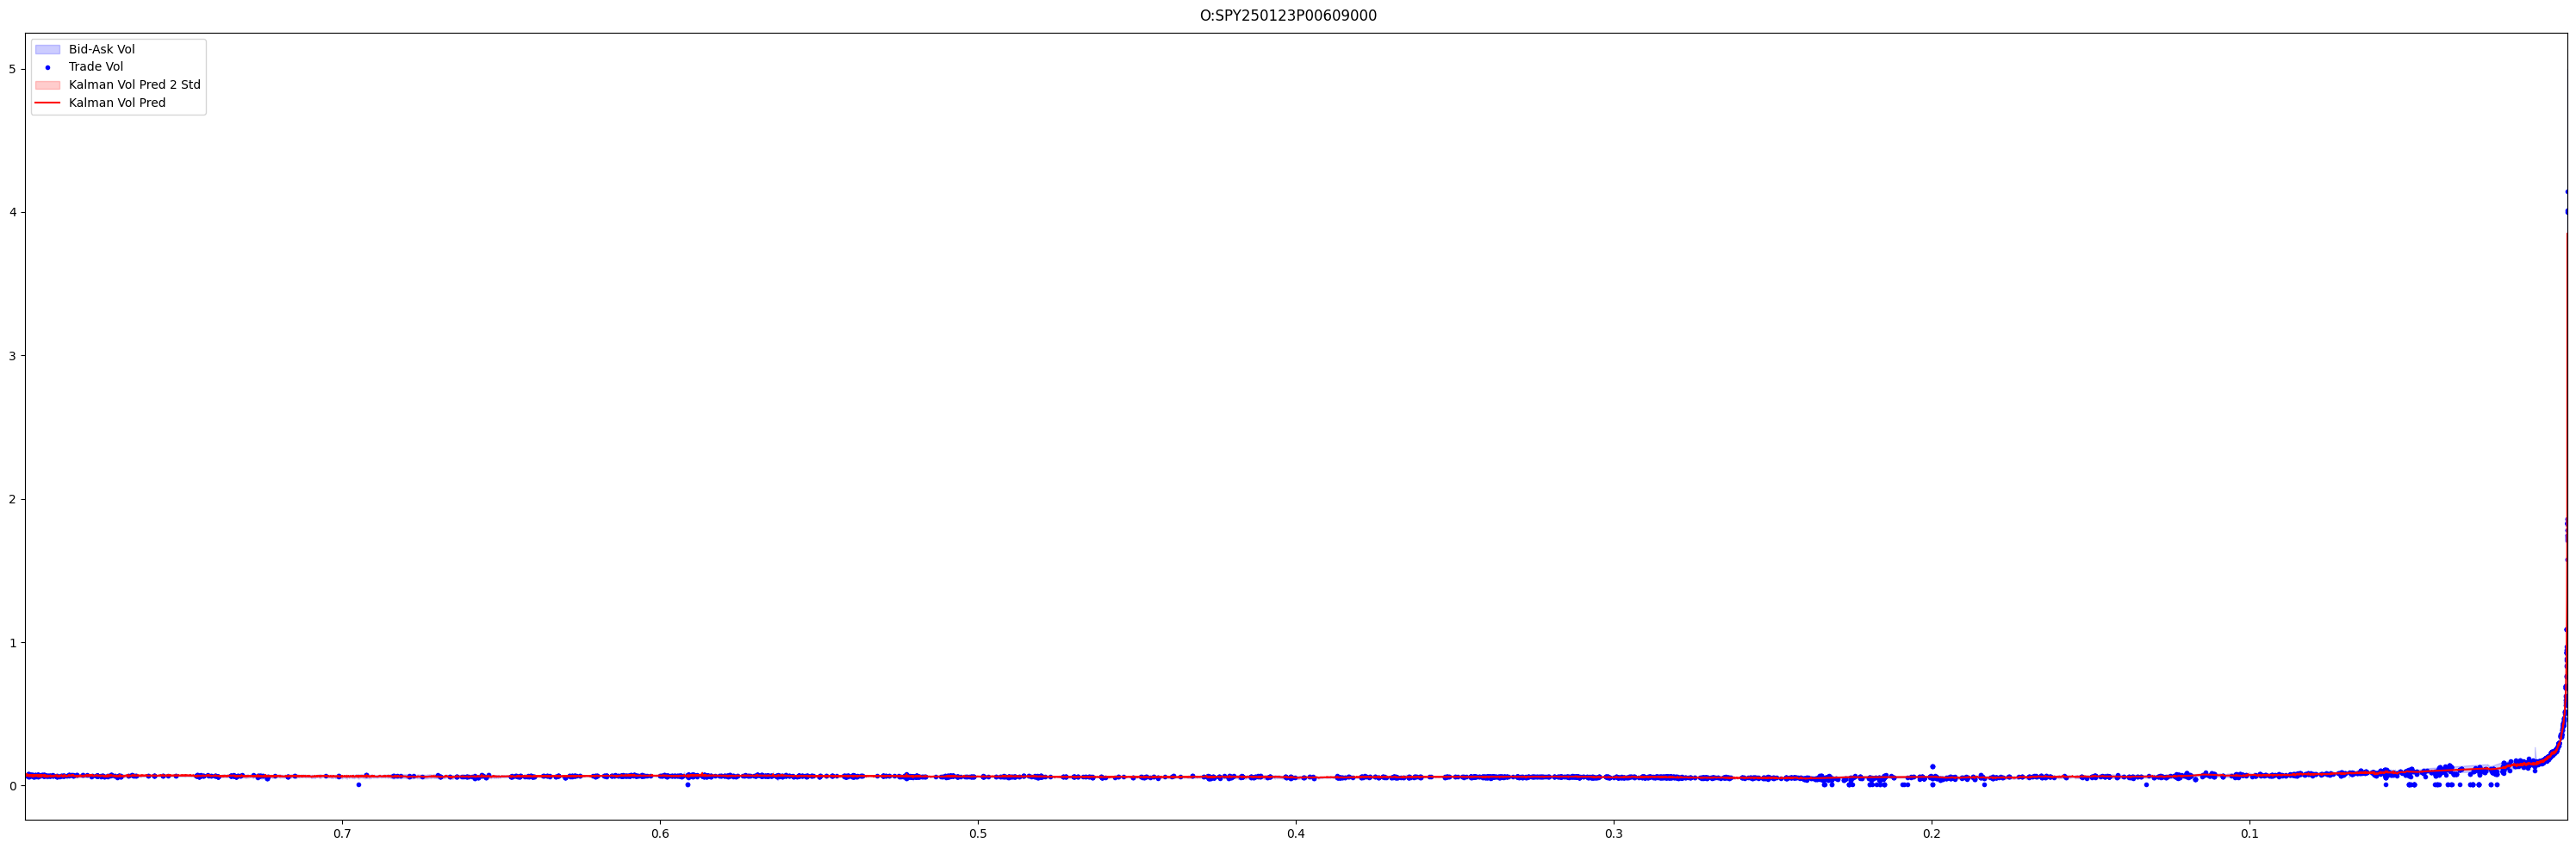

## O:SPY250123C00607000

00: Computing Kalman filter for SPY O:SPY250123C00607000 on 2025-01-23 with expiry 2025-01-23 and strike 1.001


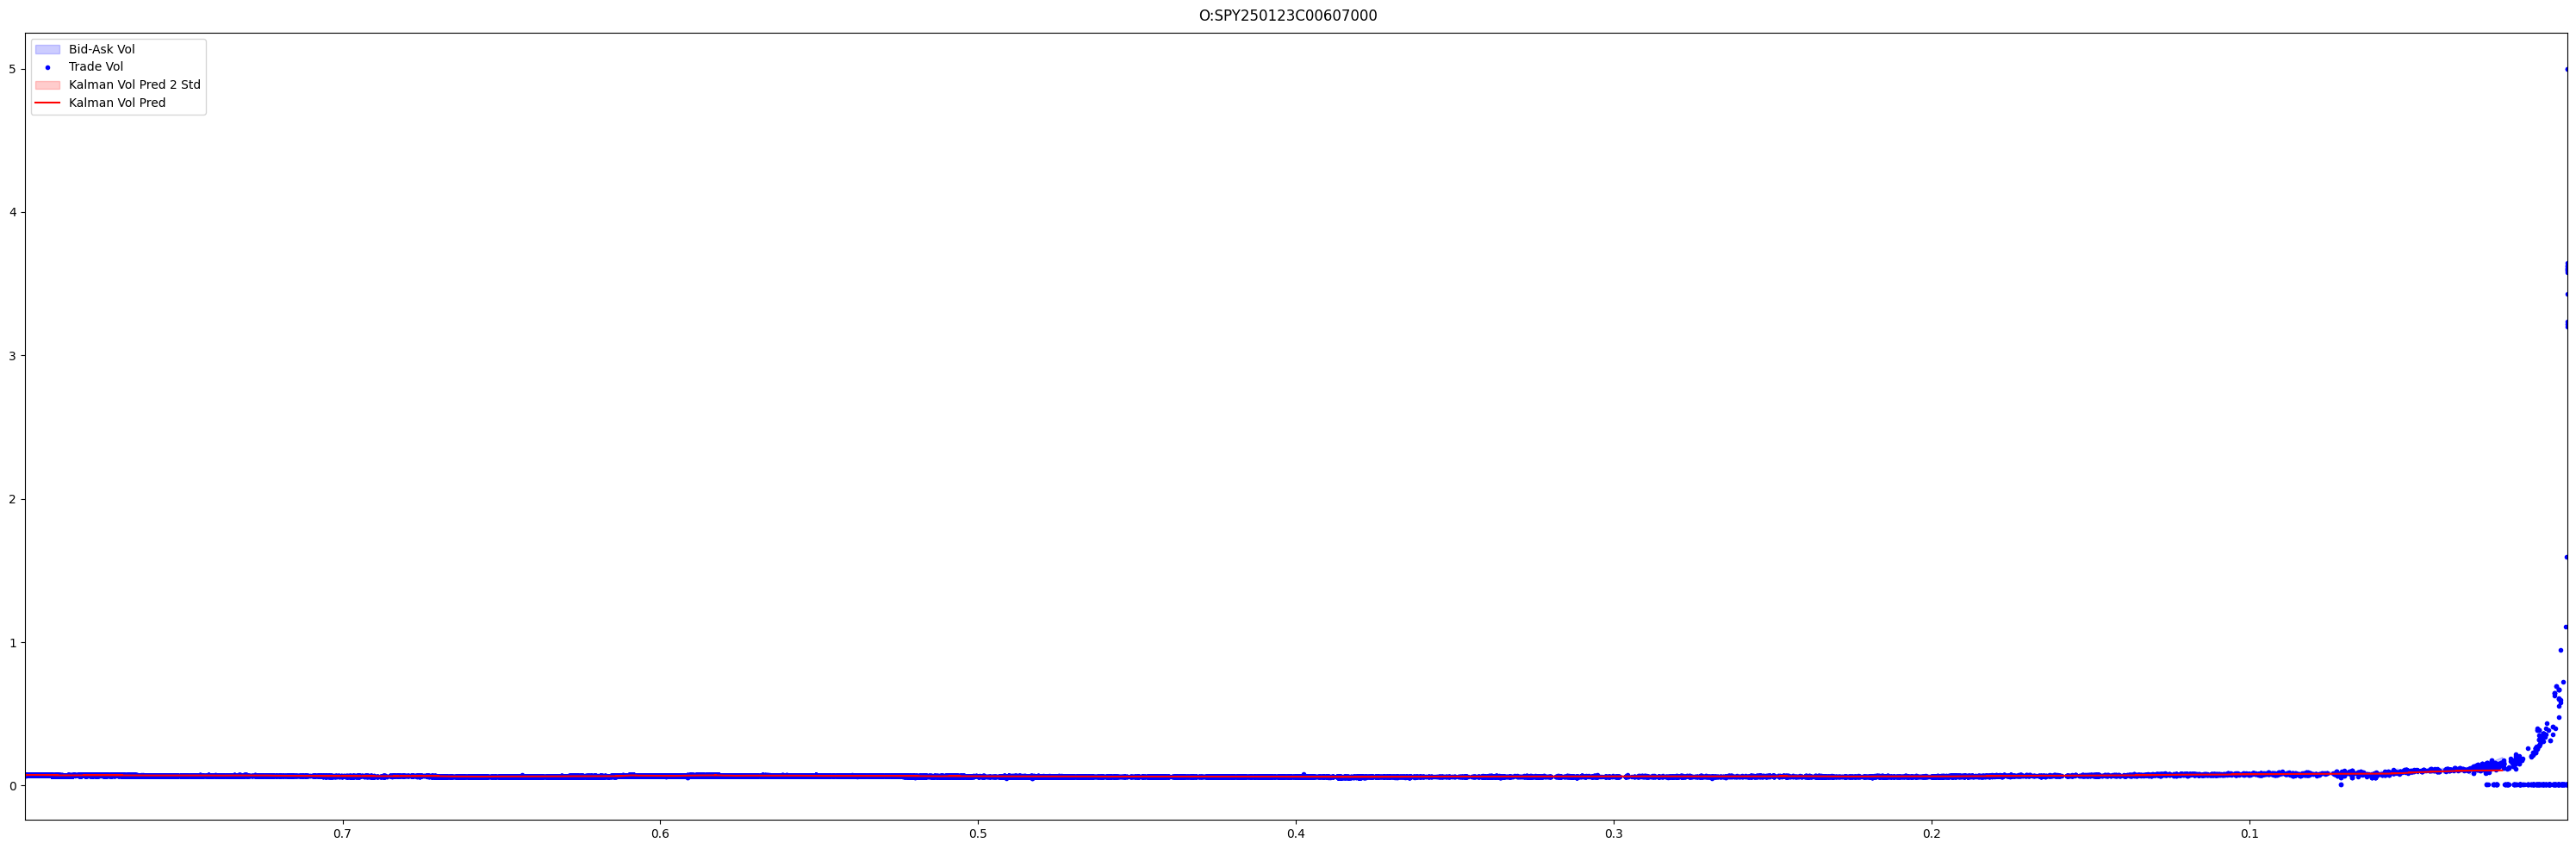

## O:SPY250123P00606000

00: Computing Kalman filter for SPY O:SPY250123P00606000 on 2025-01-23 with expiry 2025-01-23 and strike 0.999


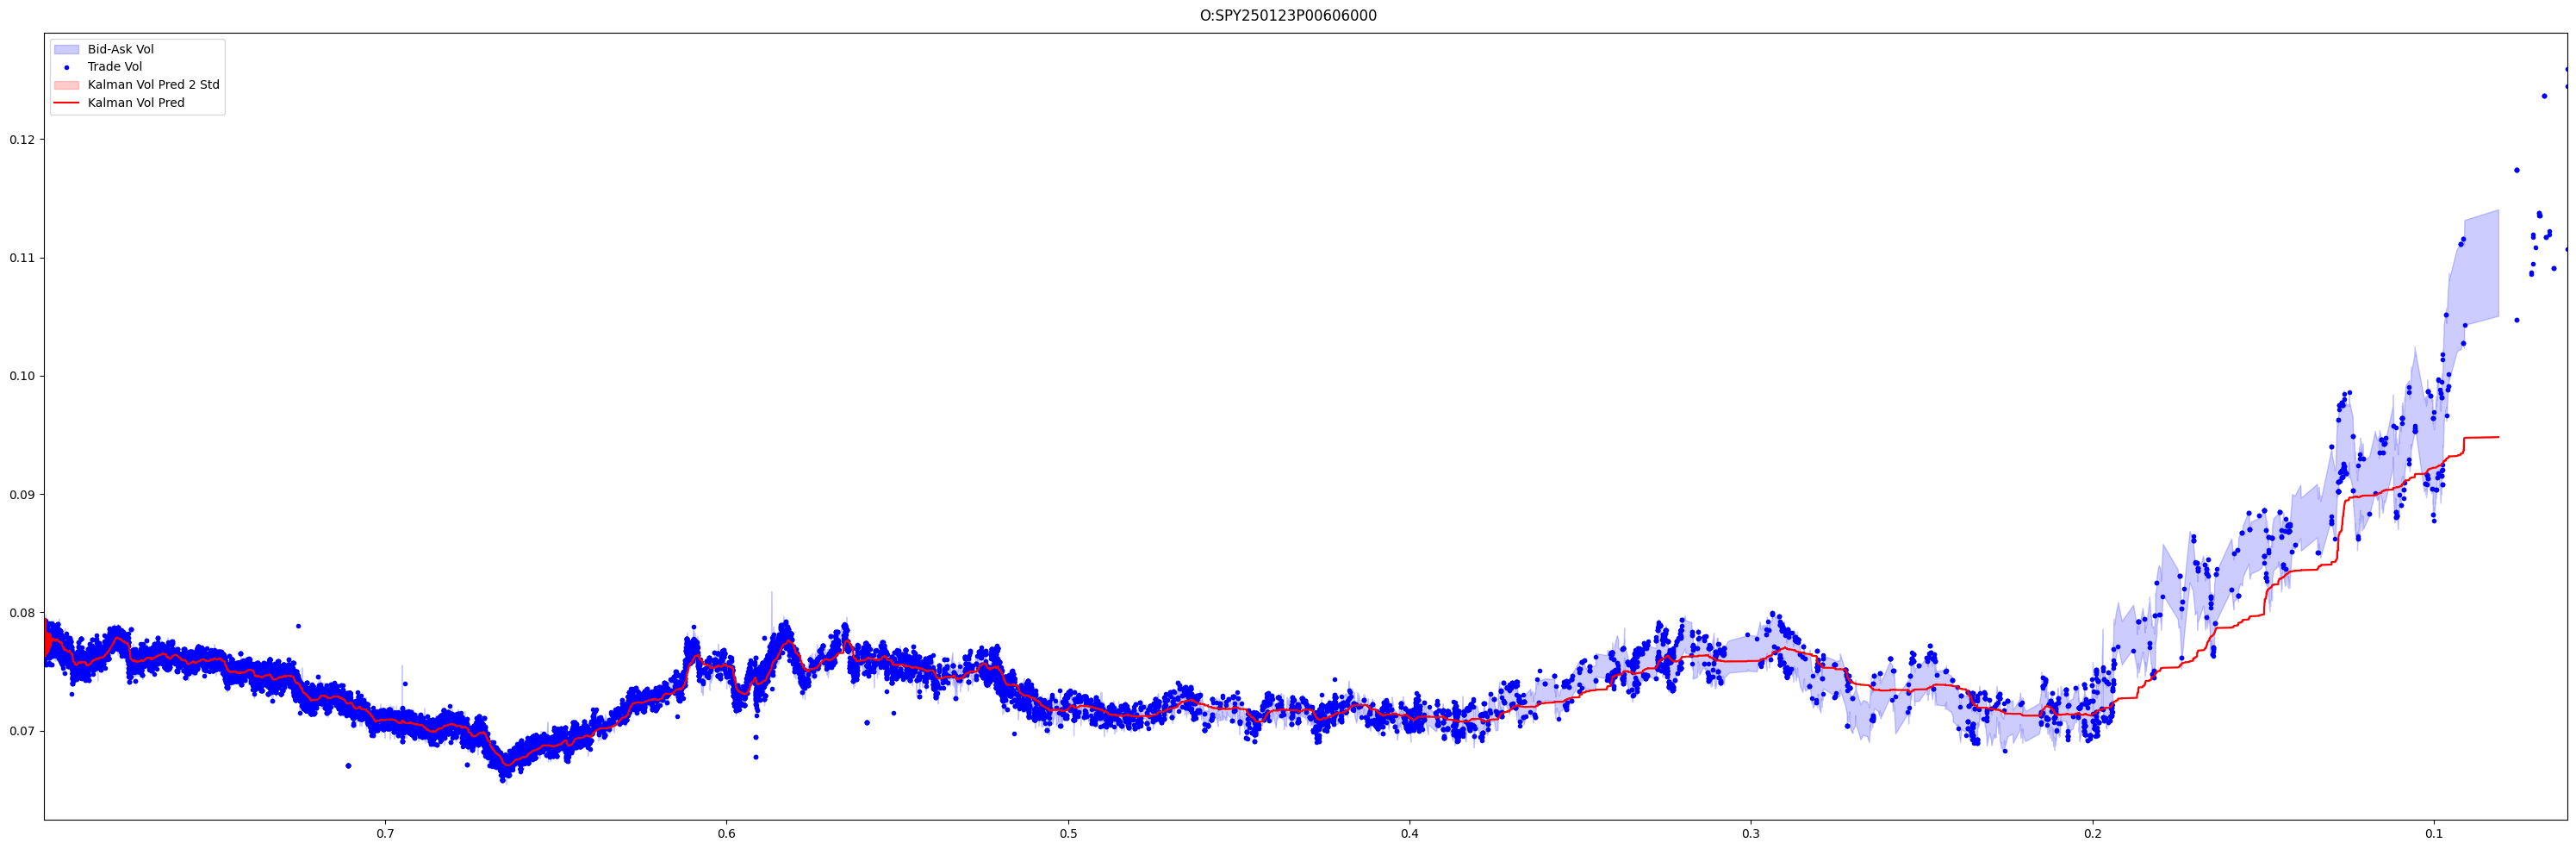

## O:SPY250123C00599000

00: Computing Kalman filter for SPY O:SPY250123C00599000 on 2025-01-23 with expiry 2025-01-23 and strike 0.988


C:\Users\hans\AppData\Local\Temp\ipykernel_35064\3455083620.py:53: UserWarning: SPY 2025-01-23 O:SPY250123C00599000: Found only 819 valid vols, which is less than 10% of the data. Kalman filter results may be unreliable.


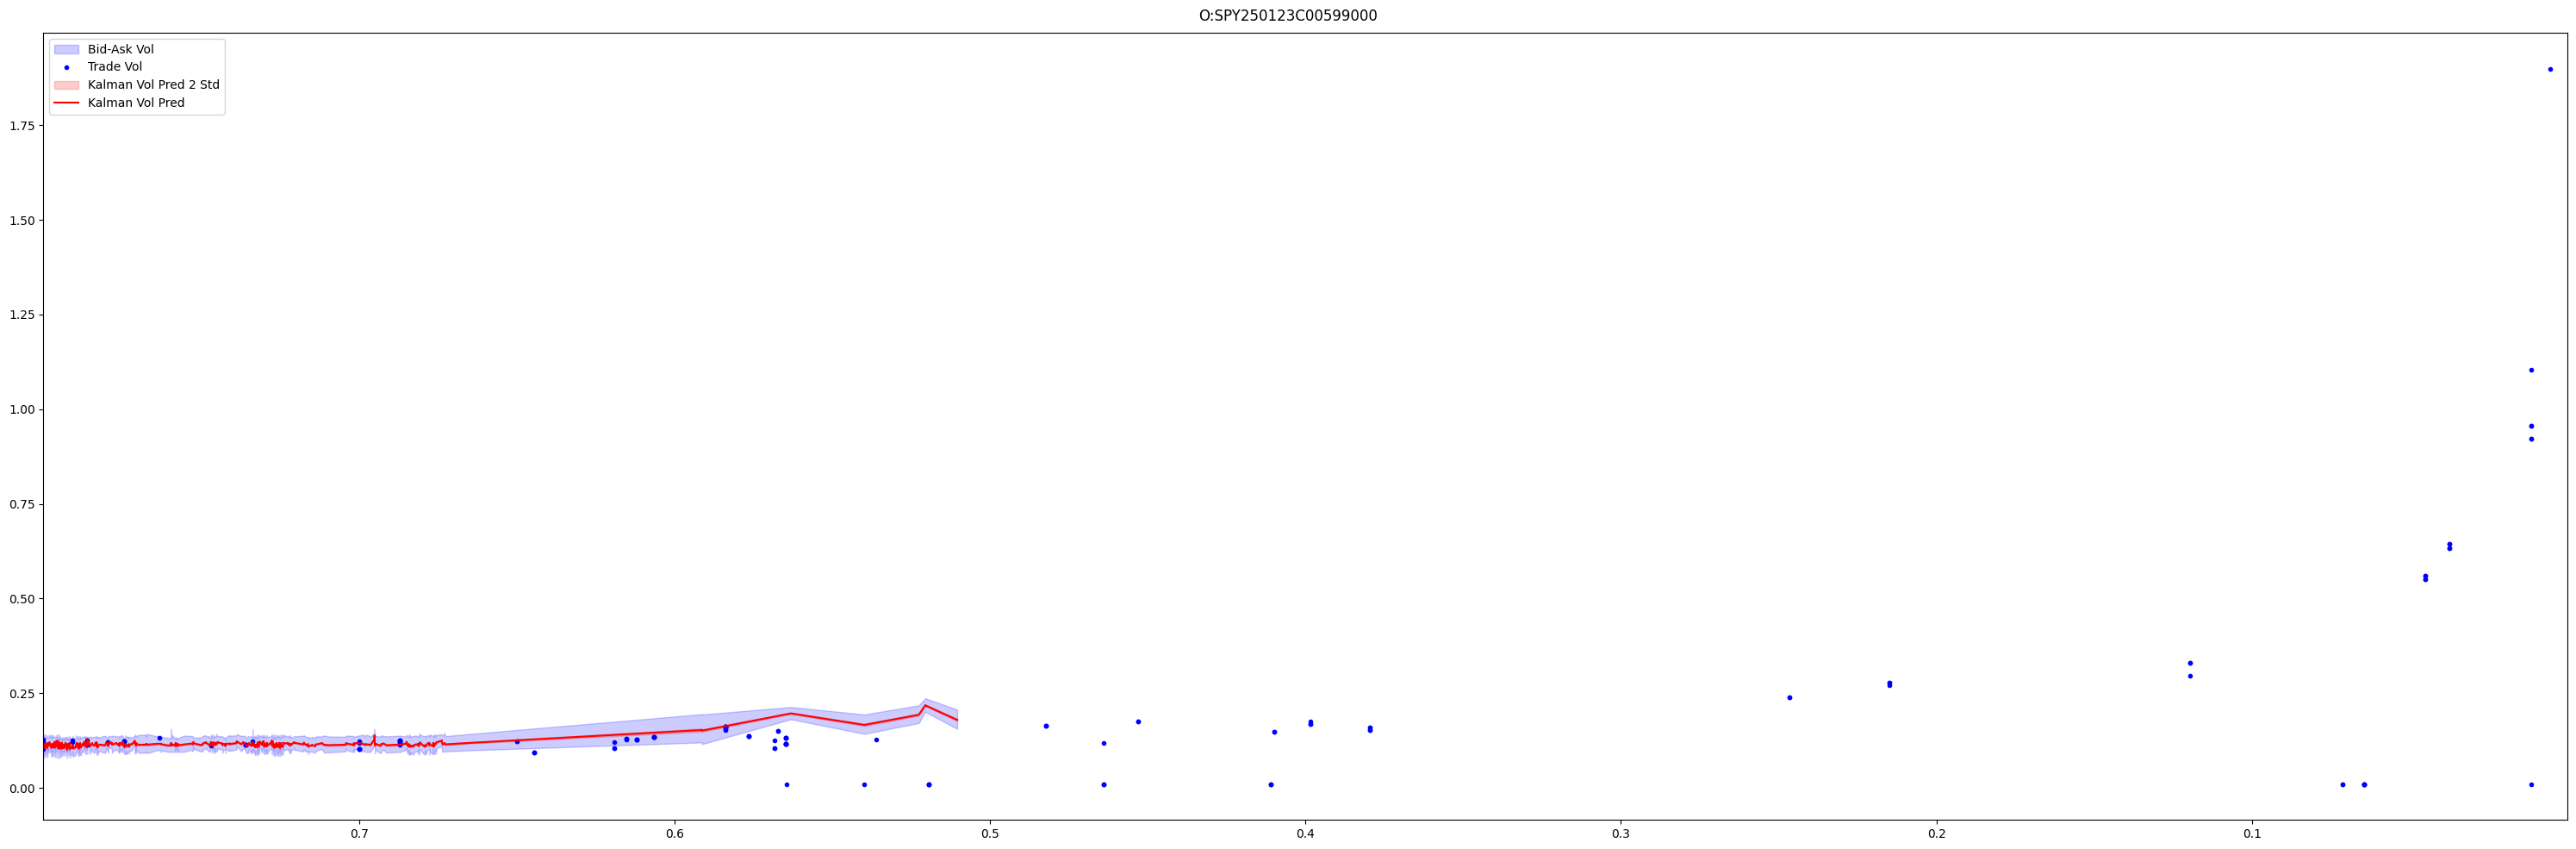

In [45]:

from os import times

from cdxcore.dynaplot import figure
from cdxcore.pretty import PrettyObject
from cdxcore.bs import bs

from quantdata.biz_calendar import DAYS_PER_YEAR
from dataclasses import dataclass
from prettytable import PrettyTable

@dataclass(frozen=True)
class KalmanFilterSettings:
    pass

def one_option_filter( option_df,
                       option_quotes_day_config, 
                       max_T : int|None = None, verbose : Context = Context.all ):
    r"""
    Kalman filter for a single option
    """

    slc    = slice(None) if max_T is None else ( option_df["t_d"] <= max_T )

    ticker = option_df["ticker"].unique().item()
    expiry = option_df["exp_date"].unique().item() 
    date   = option_df["date"].unique().item()
    strike = option_df["strike"].unique().item()
    opt_ticker = option_df["opt_ticker"].unique().item()

    with verbose.write_t(lambda : f"Computing Kalman filter for {ticker} {opt_ticker} on {date} with expiry {expiry} and strike {strike:.3f}") as tme:

        with np.errstate(divide="raise"):
            # find valid vols
            # ---------------
            SCALE = 10.

            ask_vol = option_df["ask_vol"].to_numpy()[slc]
            bid_vol = option_df["bid_vol"].to_numpy()[slc]
            shape   = ask_vol.shape
            hs_vol  = ( ask_vol - bid_vol) / 2
            time_y  = option_df["t_d"].to_numpy()[slc] / DAYS_PER_YEAR
            is_intrinsic = option_df["is_intrinsic"].to_numpy()[slc].astype(bool,copy=False) 
 
            assert np.all( np.isfinite(ask_vol) ), f"{ticker} {date} {opt_ticker}: {(~np.isfinite(ask_vol)).sum()} Non-finite ask vol, cannot run Kalman filter"
            assert np.all( np.isfinite(bid_vol) ), f"{ticker} {date} {opt_ticker}: {(~np.isfinite(bid_vol)).sum()} Non-finite bid vol, cannot run Kalman filter"

            valid_vols  = (bid_vol > option_quotes_day_config.min_vol) &\
                          (ask_vol > option_quotes_day_config.min_vol) &\
                          (bid_vol < option_quotes_day_config.max_vol) &\
                          (ask_vol < option_quotes_day_config.max_vol)
            valid_vols &= ~is_intrinsic                          
            if np.sum(valid_vols) <= 0.1*len(valid_vols):
                warnings.warn( f"{ticker} {date} {opt_ticker}: Found only {valid_vols.sum()} valid vols, which is less than 10% of the data. Kalman filter results may be unreliable.")
            assert np.all( ~valid_vols | (hs_vol > 1E-6)), f"{ticker} {date} {opt_ticker}: Found {(~valid_vols).sum()} invalid vols with half spread {np.min(hs_vol[valid_vols])}"
            del hs_vol

            ask_vol = ask_vol[valid_vols]
            bid_vol = bid_vol[valid_vols]
            time_y = time_y[valid_vols]
            assert np.min(np.diff(time_y)) > 0., f"{ticker} {date} {opt_ticker}: Found non-positive time difference {np.min(np.diff(time_y)):.4g}, cannot run Kalman filter"

            # extract rest
            # ------------

            min_log_vol   = np.log(option_quotes_day_config.min_vol)
            max_log_vol   = np.log(option_quotes_day_config.max_vol)
            log_ask_vol   = np.log( ask_vol )
            log_bid_vol   = np.log( bid_vol )
            log_mid_vol   = ( log_ask_vol + log_bid_vol ) / 2.
            log_hs_vol    = ( log_ask_vol - log_bid_vol ) / 2
            log_vol_var   = np.diff( log_mid_vol )**2 / np.diff(time_y)

            pred_log_vol    = np.zeros_like(ask_vol)
            pred_var        = np.zeros_like(ask_vol)
 
            # vol-based kalman
            # z, x ~ log vol
            # x_t = x_{t-1} + \sqrt{Q_t dt} w_t   w_t ~ N(0, Q_t)
            # z_t = x_t + v_t with v_t ~ N(0, R_t)

            pred_log_vol[0] = log_mid_vol[0]
            pred_var[0]     = max( 5*(log_hs_vol[0]/SCALE)**2/3., 1e-12 )
            for t in range(1,len(ask_vol)):
                dt          = time_y[t] - time_y[t-1]
                Q_t         = np.median( log_vol_var[:t] ) * dt # process variance of log vol, scaled by time difference
                R_t         = max( (log_hs_vol[t]/SCALE)**2/3., 1e-12 ) # variance in log vol
                vol_pred_PV = pred_var[t-1] + Q_t

                # vol
                K_t         = vol_pred_PV / ( vol_pred_PV + R_t ) 
                if not (0. <= K_t <= 1.):
                    warnings.warn(f"{ticker} {date} {opt_ticker}: Kalman gain for vol is {K_t:.4f} out of bounds at time {time_y[t]:.4f}, check vol_pred_PV {vol_pred_PV:.4e} and R_t {R_t:.4e}")
                    K_t      = np.clip( K_t, 0., 1. )
                pred_log_vol[t]  = np.clip( pred_log_vol[t-1] + K_t * ( log_mid_vol[t] - pred_log_vol[t-1] ), min_log_vol, max_log_vol )
                pred_var[t]      = max( (1 - K_t)**2 * vol_pred_PV + K_t**2 * R_t, 1e-12 )

            pred_vol_ = np.exp(pred_log_vol)
            pred_var_ = pred_var * (pred_vol_**2)  # pred_var is the var of log x -> var(x) ~ var(log x) * x^2
            pred_vol  = np.full(shape, np.nan, dtype=pred_vol_.dtype)
            pred_var  = np.full(shape, np.nan, dtype=pred_var_.dtype)  

            pred_vol[valid_vols] = pred_vol_
            pred_var[valid_vols] = pred_var_
            del pred_vol_, pred_var_

    ticker = option_df["ticker"].unique().item()
    expiry = option_df["exp_date"].unique().item() 
    date   = option_df["date"].unique().item()
    strike = option_df["strike"].unique().item()
    opt_ticker = option_df["opt_ticker"].unique().item()
    dte   = option_df["dte"].to_numpy()[slc]
    ask_vol = option_df["ask_vol"].to_numpy()[slc]
    bid_vol = option_df["bid_vol"].to_numpy()[slc]
    trade_vol = option_df["trade_vol"].to_numpy()[slc]
    trade_dte = option_df["trade_dte"].to_numpy()[slc]
    is_intrinsic = option_df["is_intrinsic"].to_numpy()[slc].astype(bool,copy=False)
    has_pred_vol = np.isfinite(pred_vol)
    has_trade_vol = np.isfinite(trade_vol)

    pred_low = pred_vol - 2*np.sqrt(pred_var)
    pred_high = pred_vol + 2*np.sqrt(pred_var)

    with figure(opt_ticker, col_size=30, row_size=10, columns=1) as fig:
        axVol= fig.add_subplot()

        axVol.fill_between( dte[~is_intrinsic], bid_vol[~is_intrinsic], ask_vol[~is_intrinsic], color="blue", alpha=0.2, label="Bid-Ask Vol")
        axVol.plot( trade_dte[has_trade_vol], trade_vol[has_trade_vol], ".", color="blue", label="Trade Vol")

        axVol.fill_between( dte[has_pred_vol], pred_low[has_pred_vol], pred_high[has_pred_vol], color="red", alpha=0.2, label="Kalman Vol Pred 2 Std")
        axVol.plot( dte[has_pred_vol], pred_vol[has_pred_vol], ",-", color="red", label="Kalman Vol Pred")
        axVol.legend(loc="upper left")

        axVol.set_xlim(dte[0], dte[-1])

opt_tickers = ["O:SPY250123P00609000", "O:SPY250123C00607000", "O:SPY250123P00606000", "O:SPY250123C00599000"]
expiry = date(2025,1,23)

for opt_ticker in opt_tickers:
    opt_df = results[expiry].filter(pl.col("opt_ticker") == opt_ticker)
    display(Markdown(f"## {opt_ticker}"))
    one_option_filter( opt_df, option_quotes_day_config, max_T=None, verbose=Context.all )

    